# Member vs. non-member scores

Plots of the attack's membership scores for members and non-members of one run, with dashed lines at each group's mean. Scores are on different scales from run to run, so each plot shows a single run: the one whose AUC is closest to the median over all runs of that setting.

In [1]:
import importlib.util
import os
import sys
import types

import numpy as np
from IPython.display import Image, display
from sklearn.metrics import roc_auc_score

# MIAClassifier.plot_scores saves under data/plots/, relative to the repository root
os.chdir(os.path.abspath(".."))
sys.path.append(os.path.abspath("src/experimentation"))
from roc_analysis import load_runs, _scores

# Load src/model/mia.py on its own: importing the model package needs gymnasium and torch,
# and mia.py uses trainer_oracle.TrainerOracle only in type hints
model_pkg = types.ModuleType("model")
model_pkg.__path__ = [os.path.abspath("src/model")]
trainer_stub = types.ModuleType("model.trainer_oracle")
trainer_stub.TrainerOracle = object
sys.modules.update({"model": model_pkg, "model.trainer_oracle": trainer_stub})
spec = importlib.util.spec_from_file_location("model.mia", "src/model/mia.py")
mia = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mia)
MIAClassifier = mia.MIAClassifier

In [2]:
def run_auc(run):
    """AUC of one saved run (lower score = member)."""
    return roc_auc_score(run["labels"], -_scores(run))


def representative_run(pattern):
    """The run matching pattern whose AUC is closest to the median AUC of all matching runs."""
    runs = load_runs(pattern)
    if not runs:
        raise FileNotFoundError(f"No runs match {pattern}")
    aucs = np.array([run_auc(r) for r in runs])
    run = runs[int(np.abs(aucs - np.median(aucs)).argmin())]
    return run, aucs


def show_scores(title, experiment, n, epochs, k=1, eps=None, xlim=(0, 1)):
    """Plots member vs. non-member scores for the representative run of one setting, on x-axis limits xlim."""
    run, aucs = representative_run(f"data/raw_results/{experiment}_({k},{eps},{n},0.5,{epochs})_r*.npz")
    scores, labels = _scores(run), run["labels"]
    members, nonmembers = scores[labels == 1], scores[labels == 0]
    name = os.path.basename(run["path"])[: -len(".npz")]
    print(f"{name}: AUC {run_auc(run):.3f} (median over {len(aucs)} runs {np.median(aucs):.3f}); "
          f"mean score member {members.mean():.4g}, non-member {nonmembers.mean():.4g}")
    MIAClassifier.plot_scores(members, nonmembers, name, title=f"{title} ($n = {n}$, AUC {run_auc(run):.2f})", xlim=xlim)
    display(Image(f"data/plots/member_nonmember_scores/{name}_score_hist.png"))

## Settings

Baselines are non-private single models (k = 1, no noise), with Q-values neither clipped nor released on the grid. Each setting's `xlim` sets its x-axis limits (default (0, 1)). The unclipped ICU-Sepsis CQL baseline needs a wider axis: its non-member scores are unbounded (median about 3, mean about 12 at n = 1000).

In [3]:
N = 1000

SETTINGS = {
    "ICU-Sepsis, Tabular Baseline": dict(experiment="sepsis-tabular-ensemble-baseline", epochs=10000, k=1, eps=None),
    "ICU-Sepsis, Tabular Ensemble ($k=50$, $\\varepsilon=10^5$)": dict(experiment="sepsis-tabular-ensemble", epochs=10000, k=50, eps=10**5),
    "ICU-Sepsis, Deep Baseline": dict(experiment="sepsis-cql-ensemble-baseline", epochs=300, k=1, eps=None, xlim=(0, 40)),
    "ICU-Sepsis, Deep Ensemble ($k=50$, $\\varepsilon=10^5$)": dict(experiment="sepsis-cql-ensemble", epochs=300, k=50, eps=10**5, xlim=(0, 1.2)),
    "Glucose, Tabular Baseline": dict(experiment="glucose-tabular-ensemble-baseline", epochs=10000, k=1, eps=None, xlim=(0, 0.07)),
    "Glucose, Deep Baseline": dict(experiment="glucose-cql-ensemble-baseline-nogrid", epochs=300, k=1, eps=None, xlim=(0, 2.5)),
    # Mitigations at a matched budget (MIT_EPS, MIT_N below). Every ensemble uses k = 50, the largest size
    "ICU-Sepsis, Tabular Ensemble ($k=50$)": dict(experiment="sepsis-tabular-ensemble", epochs=10000, k=50, eps=10**4),
    "Glucose, Tabular Ensemble ($k=50$)": dict(experiment="glucose-tabular-ensemble", epochs=10000, k=50, eps=10**4),
    "ICU-Sepsis, DP-APVI": dict(experiment="sepsis-dpapvi", epochs=1, k=1, eps=10**4),
    "Glucose, DP-APVI": dict(experiment="glucose-dpapvi", epochs=1, k=1, eps=10**4),
    "ICU-Sepsis, Deep Ensemble ($k=50$)": dict(experiment="sepsis-cql-ensemble", epochs=300, k=50, eps=10**4, xlim=(0, 1.5)),
    "Glucose, Deep Ensemble ($k=50$)": dict(experiment="glucose-cql-ensemble", epochs=300, k=50, eps=10**4, xlim=(0, 0.25)),
    "ICU-Sepsis, DP-SGD": dict(experiment="sepsis-dpsgd", epochs=300, k=1, eps=10**4, xlim=(0, 8)),
    "Glucose, DP-SGD": dict(experiment="glucose-dpsgd", epochs=300, k=1, eps=10**4, xlim=(0, 1.5)),
}

# Dataset size and privacy budget of the mitigation grids. At this budget every mechanism has useful returns,
# so the grids compare how much each leaks (the settings above hard-code eps = 10**4; change both together)
MIT_N, MIT_EPS = 1000, 10**4


ICU-Sepsis, Tabular Baseline
sepsis-tabular-ensemble-baseline_(1,None,1000,0.5,10000)_r45: AUC 0.802 (median over 50 runs 0.802); mean score member 0.04211, non-member 0.2094


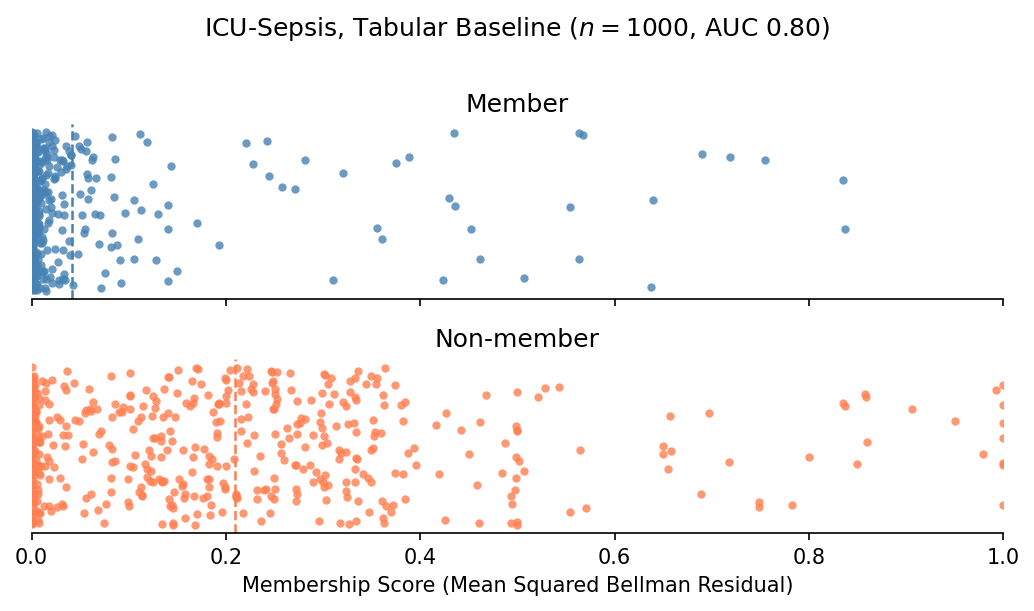

ICU-Sepsis, Tabular Ensemble ($k=50$, $\varepsilon=10^5$)
sepsis-tabular-ensemble_(50,100000,1000,0.5,10000)_r39: AUC 0.510 (median over 50 runs 0.509); mean score member 0.1999, non-member 0.2192


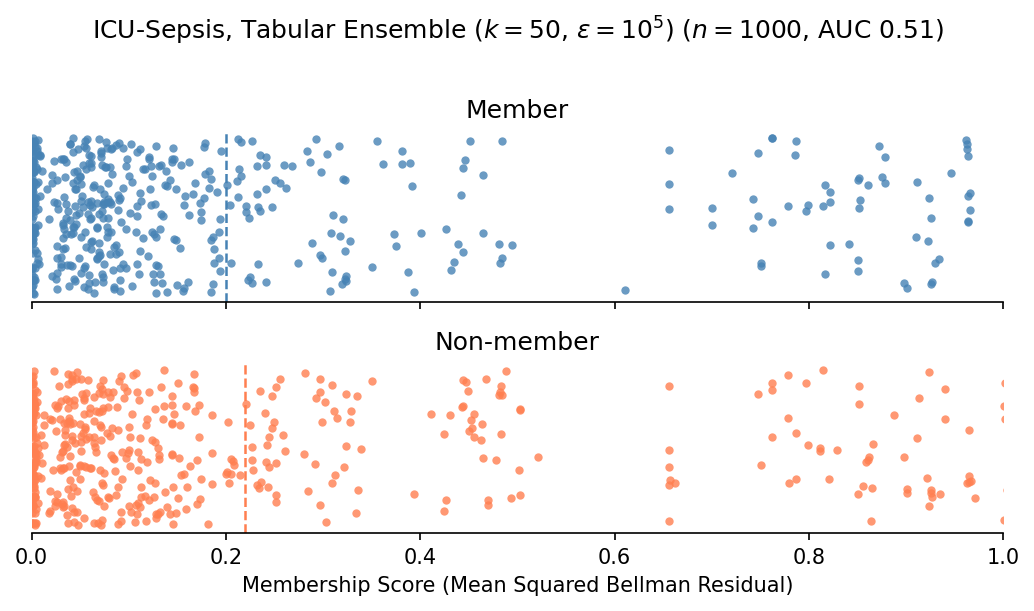

ICU-Sepsis, Deep Baseline
sepsis-cql-ensemble-baseline_(1,None,1000,0.5,300)_r33: AUC 0.753 (median over 50 runs 0.753); mean score member 0.2585, non-member 9.106


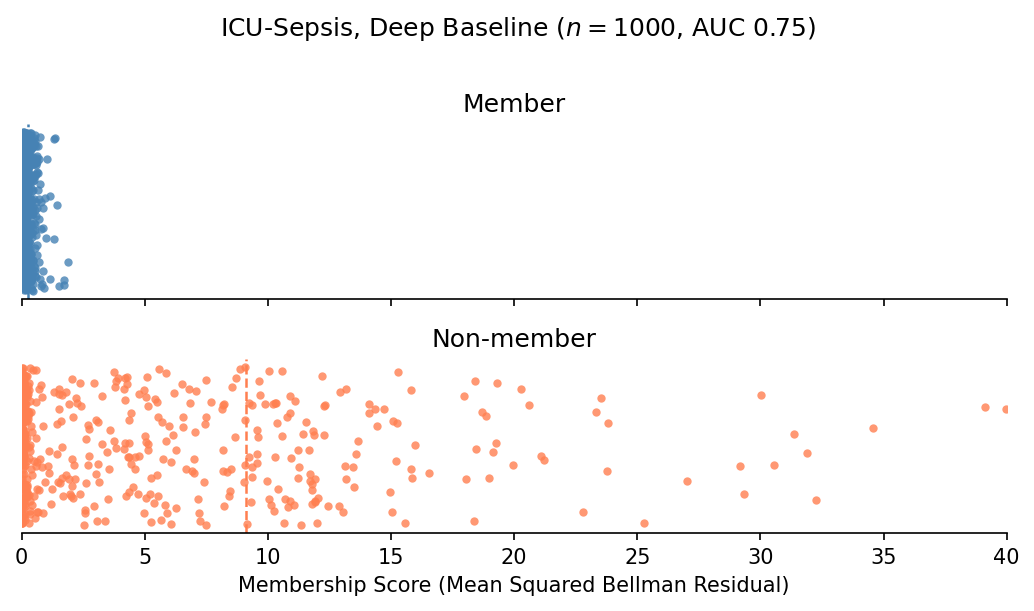

ICU-Sepsis, Deep Ensemble ($k=50$, $\varepsilon=10^5$)
sepsis-cql-ensemble_(50,100000,1000,0.5,300)_r47: AUC 0.508 (median over 50 runs 0.508); mean score member 0.2256, non-member 0.2243


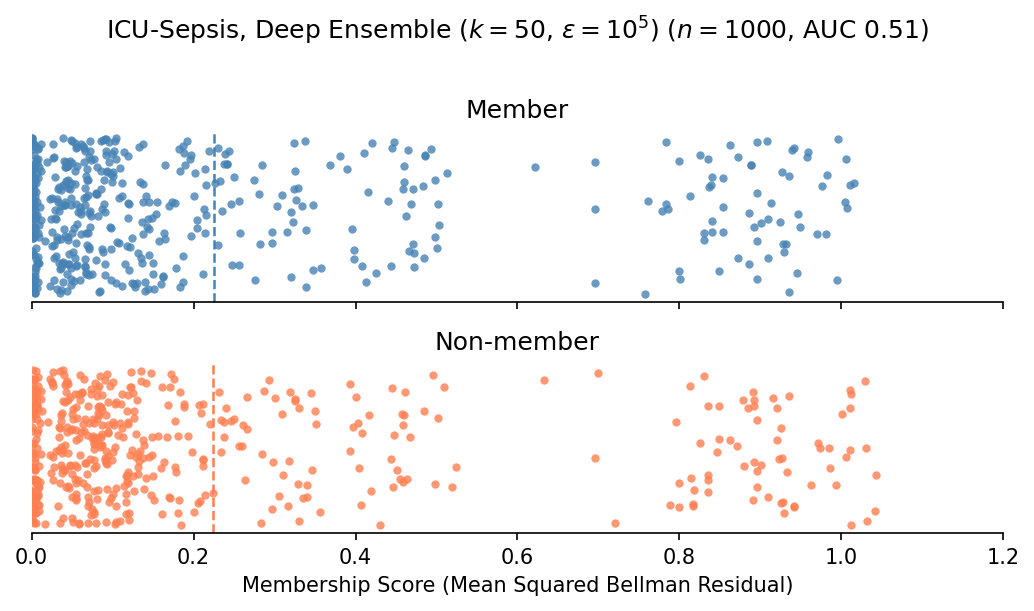

Glucose, Tabular Baseline
glucose-tabular-ensemble-baseline_(1,None,1000,0.5,10000)_r15: AUC 0.683 (median over 50 runs 0.683); mean score member 0.0003811, non-member 0.006567


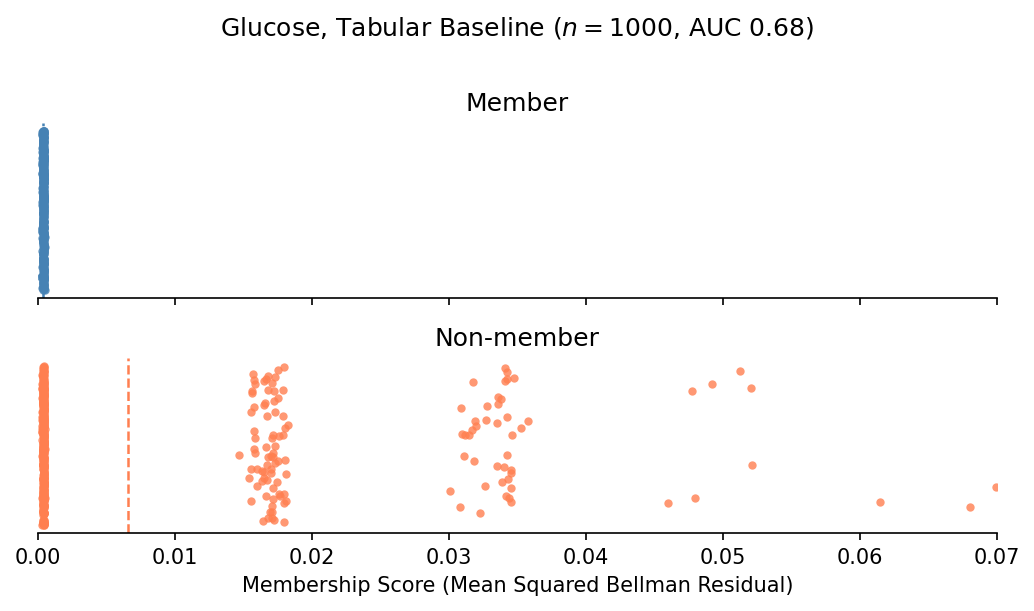

Glucose, Deep Baseline
glucose-cql-ensemble-baseline-nogrid_(1,None,1000,0.5,300)_r26: AUC 0.575 (median over 50 runs 0.575); mean score member 0.2771, non-member 0.3414


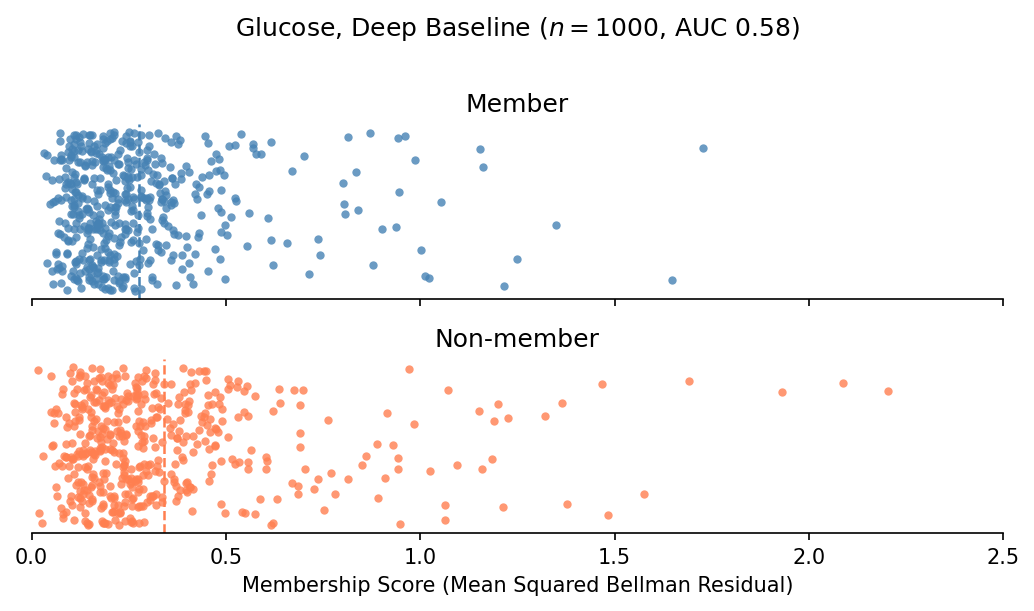

ICU-Sepsis, Tabular Ensemble ($k=50$)
sepsis-tabular-ensemble_(50,10000,1000,0.5,10000)_r13: AUC 0.508 (median over 50 runs 0.509); mean score member 0.2256, non-member 0.229


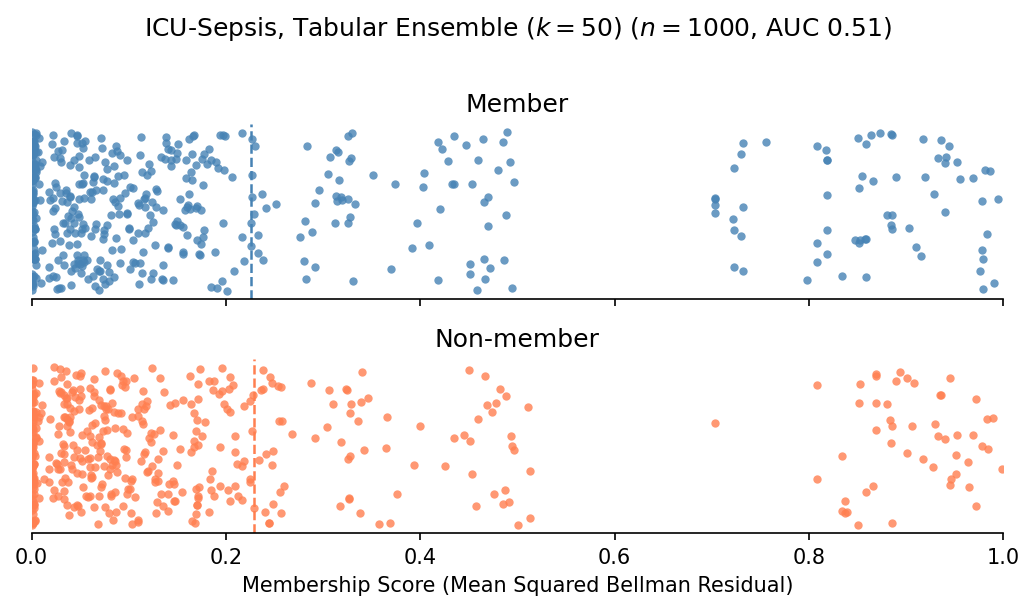

Glucose, Tabular Ensemble ($k=50$)
glucose-tabular-ensemble_(50,10000,1000,0.5,10000)_r3: AUC 0.526 (median over 50 runs 0.526); mean score member 0.02001, non-member 0.02075


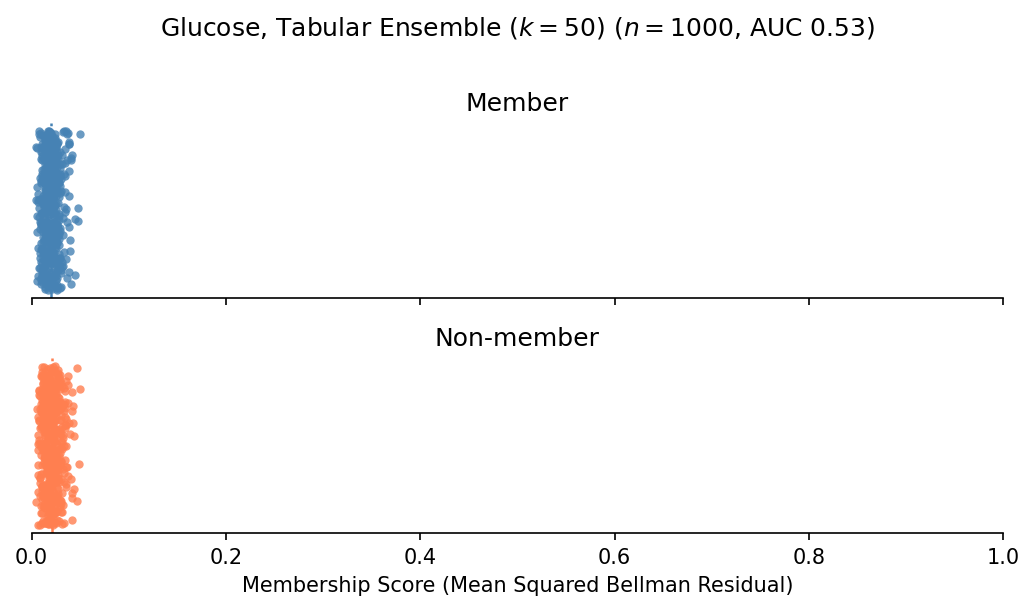

ICU-Sepsis, DP-APVI
sepsis-dpapvi_(1,10000,1000,0.5,1)_r39: AUC 0.844 (median over 50 runs 0.844); mean score member 0.0362, non-member 0.1763


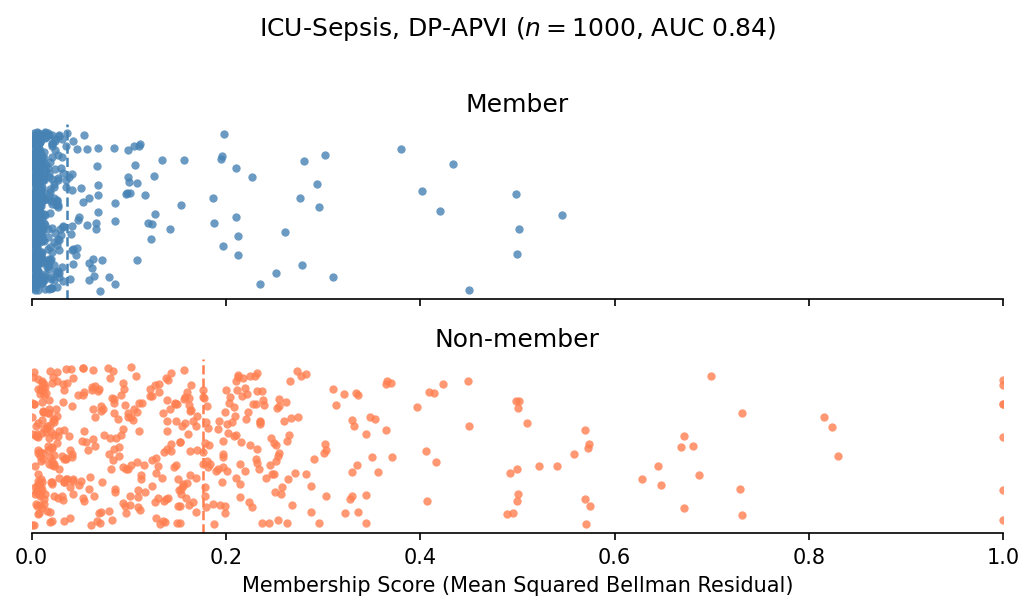

Glucose, DP-APVI
glucose-dpapvi_(1,10000,1000,0.5,1)_r45: AUC 0.637 (median over 50 runs 0.637); mean score member 0.001895, non-member 0.004358


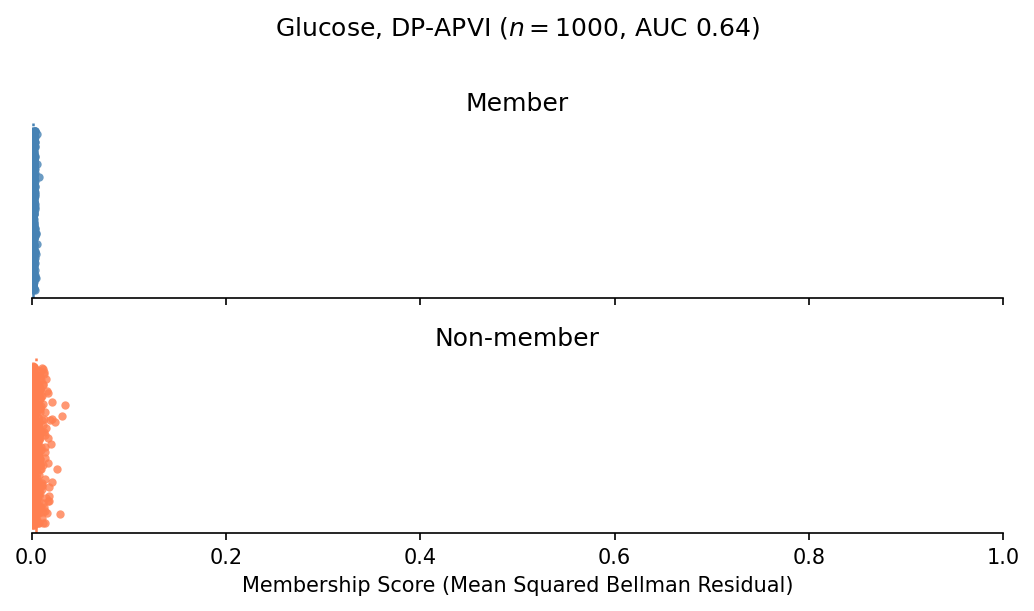

ICU-Sepsis, Deep Ensemble ($k=50$)
sepsis-cql-ensemble_(50,10000,1000,0.5,300)_r34: AUC 0.508 (median over 50 runs 0.508); mean score member 0.2416, non-member 0.2387


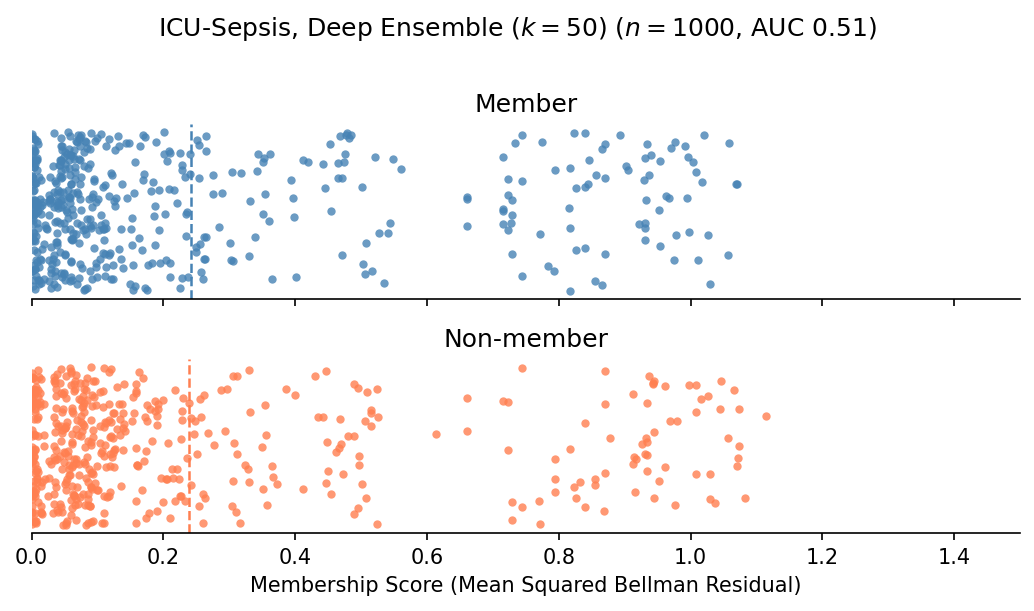

Glucose, Deep Ensemble ($k=50$)
glucose-cql-ensemble_(50,10000,1000,0.5,300)_r27: AUC 0.506 (median over 50 runs 0.506); mean score member 0.0899, non-member 0.09128


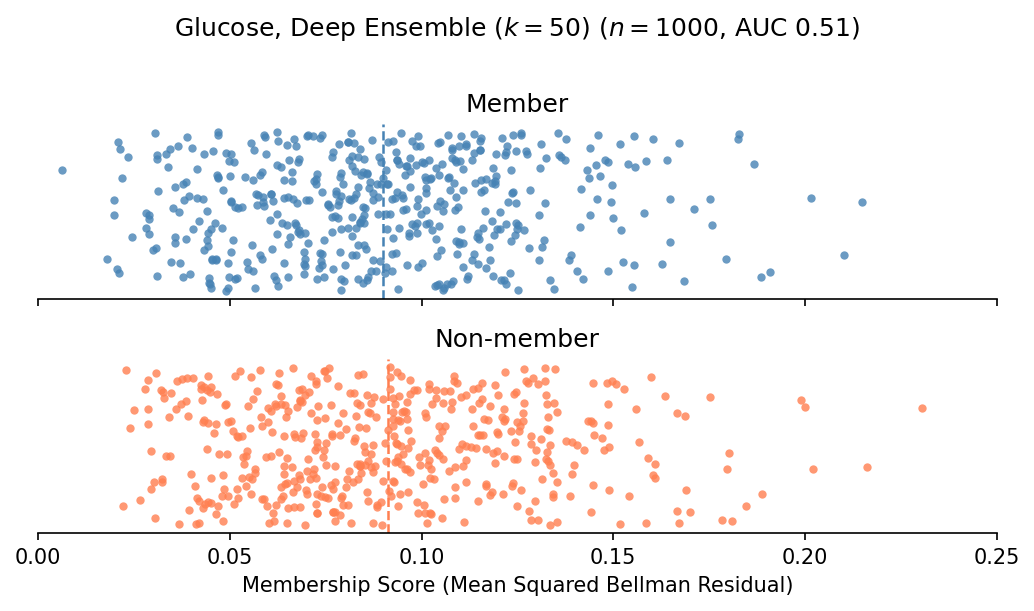

ICU-Sepsis, DP-SGD
sepsis-dpsgd_(1,10000,1000,0.5,300)_r37: AUC 0.660 (median over 50 runs 0.661); mean score member 0.7423, non-member 1.553


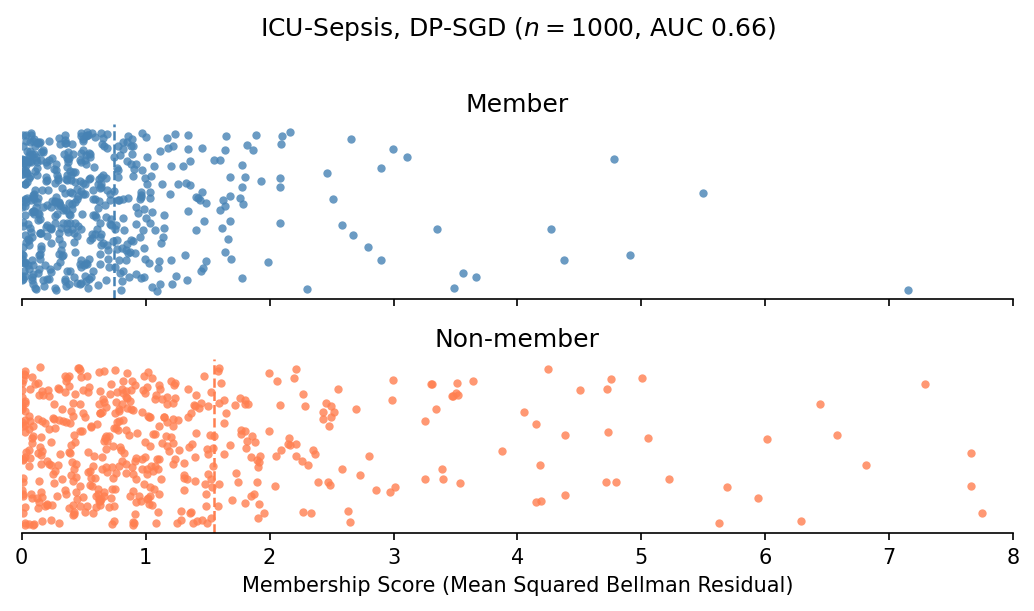

Glucose, DP-SGD
glucose-dpsgd_(1,10000,1000,0.5,300)_r27: AUC 0.508 (median over 50 runs 0.507); mean score member 0.2812, non-member 0.2874


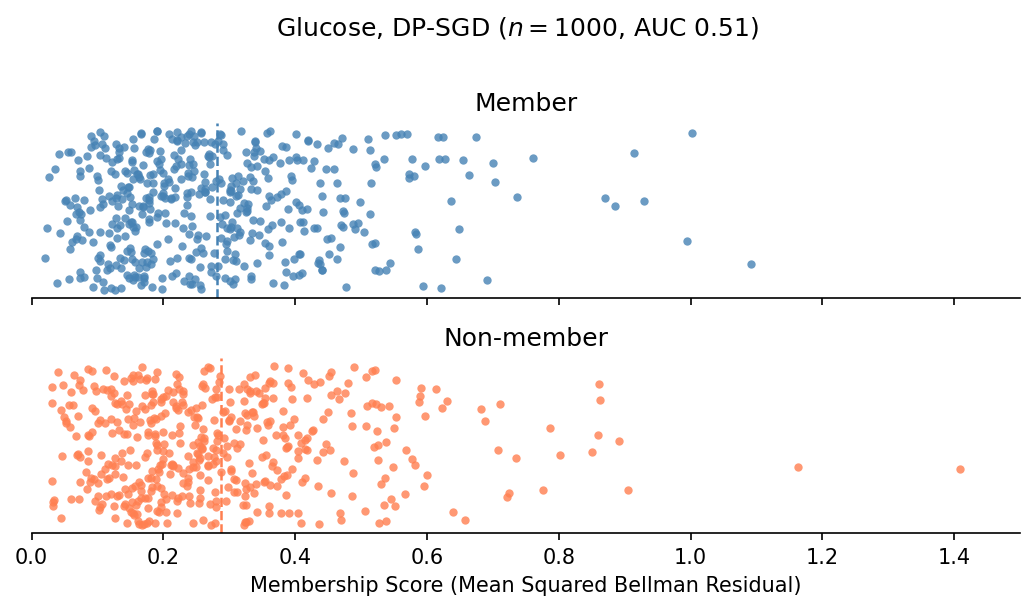

In [4]:
for title, setting in SETTINGS.items():
    print(title)
    try:
        show_scores(title, n=N, **setting)
    except FileNotFoundError as e:
        print(f"  skipped: {e}")

## Stacked comparison

Several settings' member and non-member scores on one shared x-axis, so environments can be compared directly. Each setting again shows its representative run.

In [5]:
from matplotlib import pyplot as plt


def stacked_scores(titles, n=N, xlim=None, shared_x=True, filename=None):
    """Member and non-member scores of several settings (keys of SETTINGS), stacked vertically.
    With shared_x, every panel shares one x-axis (xlim, or the widest of the settings' limits if None).
    Otherwise each setting's member/non-member pair gets its own axis, at that setting's xlim."""
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(2 * len(titles), 1, figsize=(7, 2.2 * len(titles) + 0.8))
    if shared_x and xlim is None:
        lims = [SETTINGS[t].get("xlim", (0, 1)) for t in titles]
        xlim = (min(lo for lo, _ in lims), max(hi for _, hi in lims))
    for i, title in enumerate(titles):
        s = SETTINGS[title]
        k, eps = s.get("k", 1), s.get("eps", None)
        run, _ = representative_run(
            f"data/raw_results/{s['experiment']}_({k},{eps},{n},0.5,{s['epochs']})_r*.npz"
        )
        scores, labels = _scores(run), run["labels"]
        top, bottom = axes[2 * i], axes[2 * i + 1]
        MIAClassifier.draw_score_strip(
            top, scores[labels == 1], "steelblue",
            f"{title} ($n = {n}$, AUC {run_auc(run):.2f}): members", rng,
        )
        MIAClassifier.draw_score_strip(bottom, scores[labels == 0], "coral", "Non-members", rng)
        for ax in (top, bottom):
            ax.set_xlim(*(xlim if shared_x else s.get("xlim", (0, 1))))
        top.tick_params(labelbottom=False)
        if shared_x and i < len(titles) - 1:
            bottom.tick_params(labelbottom=False)
    axes[-1].set_xlabel("Membership Score (Mean Squared Bellman Residual)")
    fig.tight_layout()
    if filename is not None:
        fig.savefig(f"data/plots/member_nonmember_scores/{filename}", dpi=150, bbox_inches="tight")
    plt.show()

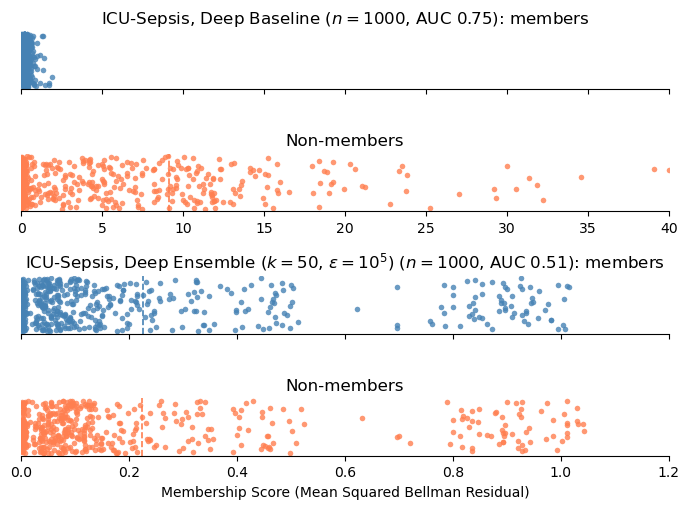

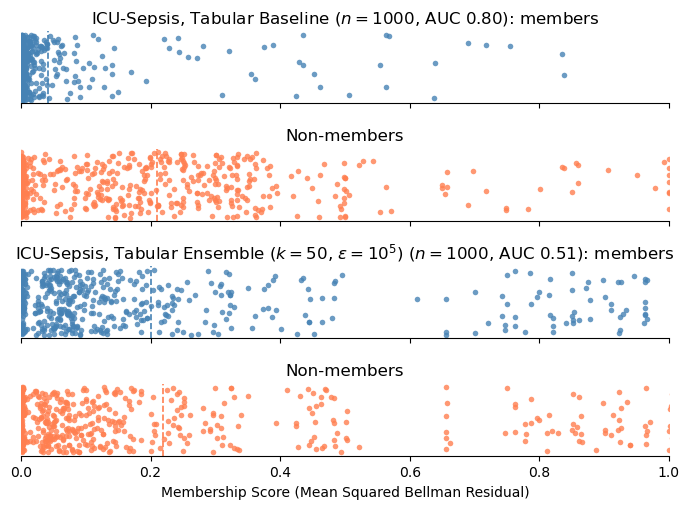

In [6]:
# Each setting on its own x-axis: the unclipped baseline's scores run to about 40, the ensemble's stay below 1
stacked_scores(["ICU-Sepsis, Deep Baseline", "ICU-Sepsis, Deep Ensemble ($k=50$, $\\varepsilon=10^5$)"], shared_x=False, filename=f"stacked_cql_n{N}.png")
stacked_scores(["ICU-Sepsis, Tabular Baseline", "ICU-Sepsis, Tabular Ensemble ($k=50$, $\\varepsilon=10^5$)"], filename=f"stacked_tabular_n{N}.png")

## Grid comparison

Settings in a grid (rows of SETTINGS keys), one panel per setting, each panel showing its representative run's members above its non-members. Every panel has its own x-axis at its setting's `xlim`, since scores differ by orders of magnitude between settings. Scores beyond `xlim` are drawn at the axis edge. The baselines get one row each (tabular, then deep); 2 x 2 grids suit the mitigations.

In [7]:
def eps_label(eps):
    """The privacy budget for a panel title: empty for non-private settings, else ", eps = 10^x"."""
    if eps is None:
        return ""
    exponent = np.log10(eps)
    value = f"10^{{{int(exponent)}}}" if exponent.is_integer() else f"{eps:g}"
    return f", $\\varepsilon = {value}$"


def grid_scores(grid, n=N, col_xlims=None, filename=None):
    """Member and non-member scores of a grid of settings (rows of SETTINGS keys).
    Each panel is one setting: members on top, non-members below, sharing one x-axis.
    n is one dataset size for every row, or a list with one per row (e.g. to compare n down a column).
    col_xlims gives each column's x-axis limits; by default each panel uses its setting's xlim."""
    rng = np.random.default_rng(0)
    n_rows, n_cols = len(grid), len(grid[0])
    row_ns = list(n) if isinstance(n, (list, tuple)) else [n] * n_rows
    fig = plt.figure(figsize=(5 * n_cols, 3.2 * n_rows))
    outer = fig.add_gridspec(n_rows, n_cols, hspace=0.55, wspace=0.15)
    for r, row in enumerate(grid):
        for c, title in enumerate(row):
            s, n_r = SETTINGS[title], row_ns[r]
            k, eps = s.get("k", 1), s.get("eps", None)
            xlim = col_xlims[c] if col_xlims is not None else s.get("xlim", (0, 1))
            run, _ = representative_run(
                f"data/raw_results/{s['experiment']}_({k},{eps},{n_r},0.5,{s['epochs']})_r*.npz"
            )
            scores, labels = _scores(run), run["labels"]
            inner = outer[r, c].subgridspec(2, 1, hspace=0.15)
            top, bottom = fig.add_subplot(inner[0]), fig.add_subplot(inner[1])
            for ax, group, color, label in ((top, 1, "steelblue", "Members"), (bottom, 0, "coral", "Non-members")):
                MIAClassifier.draw_score_strip(ax, np.clip(scores[labels == group], *xlim), color, None, rng)
                ax.set_xlim(*xlim)
                ax.set_ylabel(label, fontsize=9)
            top.set_title(f"{title}\n($n = {n_r}${eps_label(eps)}, AUC {run_auc(run):.2f})", fontsize=10)
            top.tick_params(labelbottom=False)
            if r == n_rows - 1:
                bottom.set_xlabel("Membership Score (Mean Squared Bellman Residual)")
    if filename is not None:
        fig.savefig(f"data/plots/member_nonmember_scores/{filename}", dpi=150, bbox_inches="tight")
    plt.show()



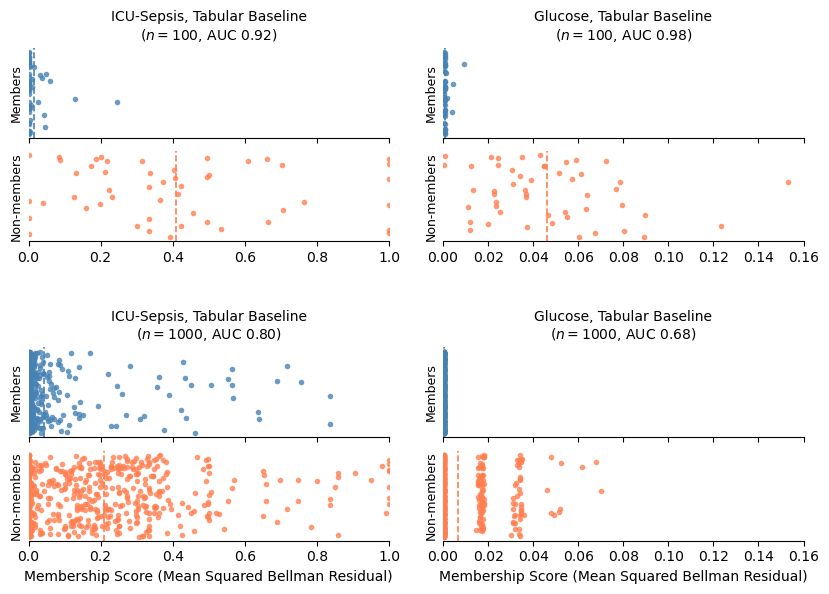

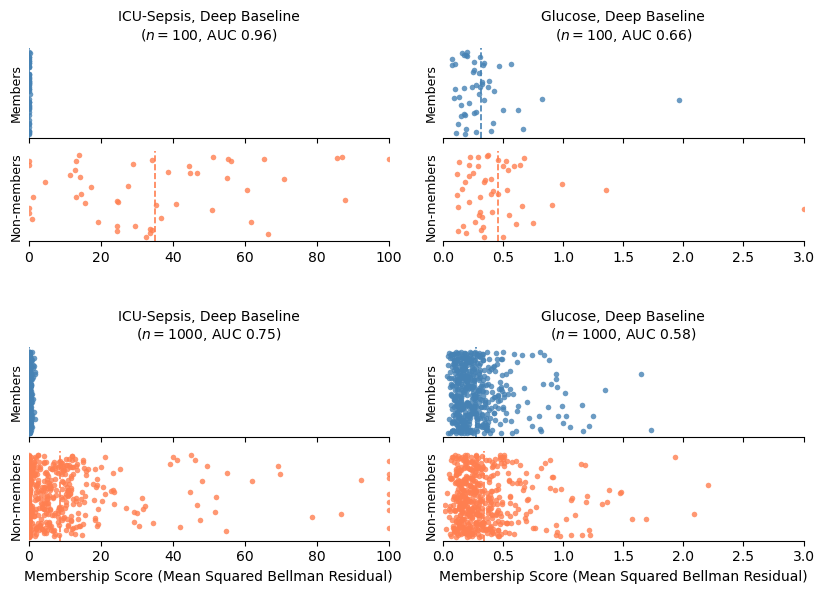

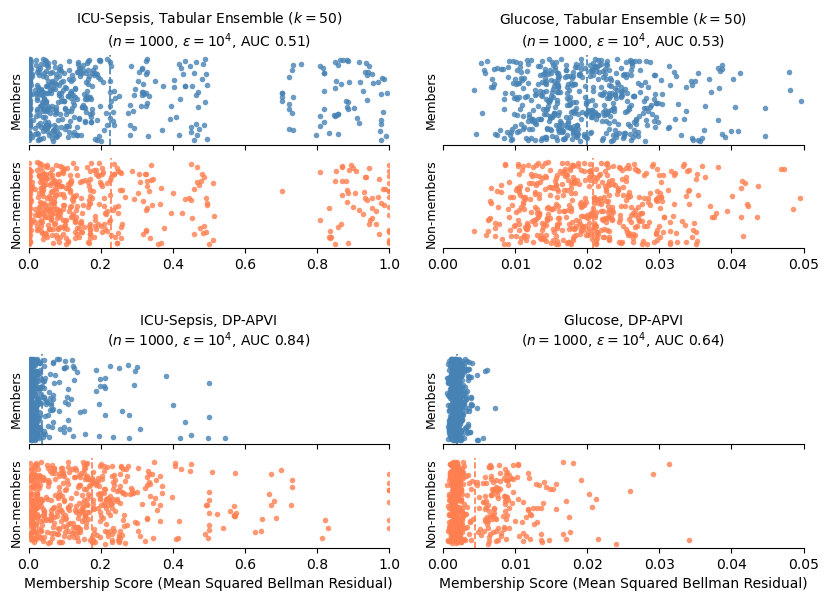

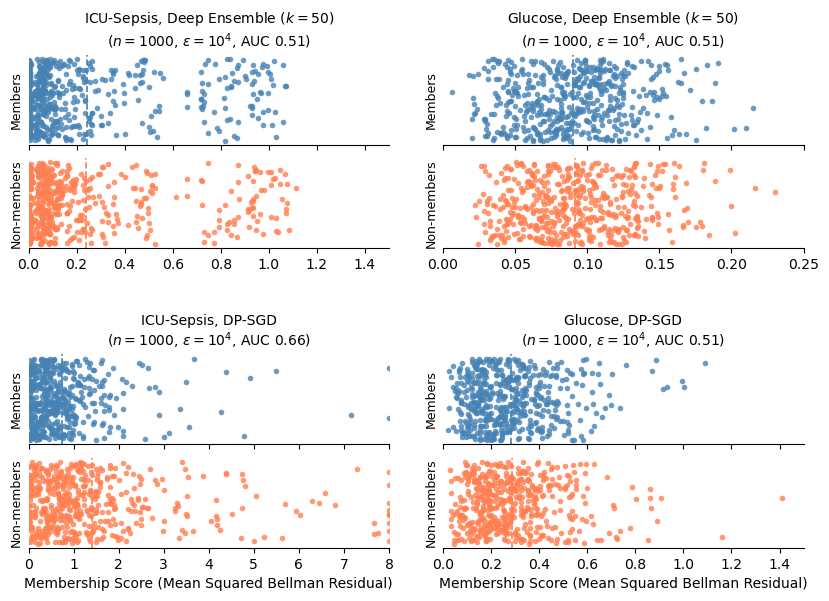

In [8]:
# 1. Tabular baselines, n = 100 vs. 1000. Glucose's n = 100 non-members reach about 0.15
grid_scores(
    [["ICU-Sepsis, Tabular Baseline", "Glucose, Tabular Baseline"]] * 2,
    n=[100, 1000], col_xlims=[(0, 1), (0, 0.16)],
    filename="baselines_tabular_n100_n1000.png",
)

# 2. Deep (CQL) baselines, n = 100 vs. 1000. ICU-Sepsis's unclipped non-member scores reach about 100 at n = 100
grid_scores(
    [["ICU-Sepsis, Deep Baseline", "Glucose, Deep Baseline"]] * 2,
    n=[100, 1000], col_xlims=[(0, 100), (0, 3)],
    filename="baselines_cql_n100_n1000.png",
)

# 3. Tabular mitigations: ensemble vs. DP-APVI
grid_scores(
    [["ICU-Sepsis, Tabular Ensemble ($k=50$)", "Glucose, Tabular Ensemble ($k=50$)"],
     ["ICU-Sepsis, DP-APVI", "Glucose, DP-APVI"]],
    n=MIT_N, col_xlims=[(0, 1), (0, 0.05)],
    filename=f"mitigations_tabular_n{MIT_N}_eps{MIT_EPS}.png",
)

# 4. Deep mitigations: CQL ensemble vs. DP-SGD (each panel on its own axis)
grid_scores(
    [["ICU-Sepsis, Deep Ensemble ($k=50$)", "Glucose, Deep Ensemble ($k=50$)"],
     ["ICU-Sepsis, DP-SGD", "Glucose, DP-SGD"]],
    n=MIT_N,
    filename=f"mitigations_cql_n{MIT_N}_eps{MIT_EPS}.png",
)
